# The current models on the 36 DOLAP 2026 tasks

The DOLAP 2026 paper evaluated six proprietary models on 36 airport tasks. Our current experiments use open-weight
models, other tasks (airports v5) and new prompts, and score much lower. This report puts the current models on the
**same 36 tasks**, so that the remaining differences can be separated.

| Run | Models | Prompts | Runs per setup | Repair call | Source |
|---|---|---|---|---|---|
| **DOLAP (published)** | Claude Sonnet 4.5, Claude Haiku 4.5, GPT-5, GPT-5 Mini, Gemini 2.5 Pro, Gemini 2.5 Flash | the 9 published prompts | 5, voted | no | the paper's voted answers (`data/dolap2026/published_results`) |
| **Lineup, DOLAP protocol** | gpt-oss:20b, gemma4:31b, gpt-oss:120b, deepseek-v4.1-flash | the 9 published prompts | 5, voted | no | `configs/strategy_a_dolap2026.yaml` |
| **Lineup, new protocol** | the same 4 | the 9 prompts of the new version (Figure 2), with property notes and the v5 examples | 3, voted | yes | `configs/strategy_a_dolap2026_newprompts.yaml` |

Each prompt runs **without and with context**, on the exact published inputs: the airport's own properties on the
`input:` line and, with context, the published context block (neighbouring airports and the city). So each model has
18 setups. mistral-large-3, the fifth model of the lineup, was retired by Ollama Cloud and could not be run.

**Two scorings**, on the voted answer of each (model, setup, task):

- **DOLAP scoring**, as in the paper: every answered property with a ground truth is compared (asked or not),
  unanswered properties are ignored, lenient tolerance; precision is 1 by construction and
  DOLAP F1 = 2·acc / (1 + acc), acc = correct / answered. Table 3 of the paper reports the best of the 18 setups.
- **Our scoring**, as in the current experiments: only the asked properties, each correct (c), wrong (w) or
  abstained (a), with the current tolerance. **Main metrics: F1 = 2c / (2c + 2w + a) and precision = c / (c + w)**;
  beside them F1 ign = 2c / (2c + w), the DOLAP formula on the asked properties.

Unless stated otherwise, numbers pool all 18 setups (micro-average over the scored properties).

In [1]:
from pathlib import Path
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
import sys; sys.path.insert(0, str(ROOT / "notebooks"))
from evaluation import dolap as D
import paper_report_lib as L   # chart style and colours of the other reports

TASKS = D.load_tasks(ROOT / "tasks/airports/dolap2026/tasks.csv")
NV = D.load_node_values(ROOT / "data/dolap2026/ground_truth.csv")
RES = {"lineup, DOLAP protocol": ROOT / "results/airports/dolap2026/strategy_a",
       "lineup, new protocol": ROOT / "results/airports/dolap2026/strategy_a_newprompts"}
LINEUP = ["cloud-gpt-oss-20b", "cloud-gemma4-31b", "cloud-gpt-oss-120b", "cloud-deepseek-v4.1-flash"]
PUB = ["GPT-5", "GPT-5 Mini", "Gemini 2.5 Pro", "Gemini 2.5 Flash", "Claude Sonnet 4.5", "Claude Haiku 4.5"]
PROMPT = {"compact": "compact", "zero": "zero-shot", "few1": "1-shot", "few3": "3-shot", "few5": "5-shot",
          "zerocot": "zero-shot + CoT", "1cot": "1-shot + CoT", "3cot": "3-shot + CoT", "5cot": "5-shot + CoT",
          "few_1": "1-shot", "few_3": "3-shot", "few_5": "5-shot",
          "fewcot_1": "1-shot + CoT", "fewcot_3": "3-shot + CoT", "fewcot_5": "5-shot + CoT"}
PORDER = ["compact", "zero-shot", "zero-shot + CoT", "1-shot", "1-shot + CoT", "3-shot", "3-shot + CoT", "5-shot", "5-shot + CoT"]
PCOLOR = dict(zip(PUB, ["#2b2b29", "#55544f", "#6b6a66", "#8a8984", "#a3a29d", "#bdbcb6"]))
COLOR = {**{L.MNAME[m]: L.MCOLOR[m] for m in LINEUP}, **PCOLOR}

## 1. Runs and voting

In [2]:
frames, status = [], []
for proto, path in RES.items():
    if not (path / "results.csv").exists():
        continue
    runs = D.load_runs(path)
    runs = runs[runs.model.isin(LINEUP)]
    if runs.empty:
        continue
    status.append(runs.assign(protocol=proto).groupby(["protocol", "model"]).agg(
        runs=("run_index", "size"), ok=("status", lambda s: (s == "ok").mean()),
        tasks=("task_id", "nunique"), setups=("variant", "nunique")))
    # complete models only: every task × setup has its runs
    need = runs.groupby("model").variant.nunique().max()
    cover = runs.groupby(["model", "variant"]).task_id.nunique().groupby("model").min()
    full = [m for m in cover.index if cover[m] == len(TASKS) and runs[runs.model == m].variant.nunique() == need]
    if not full:
        continue
    v = D.voted_from_runs(runs[runs.model.isin(full)], TASKS)
    v["context"] = v.variant.str.contains("_ctx")
    v["prompt"] = v.variant.str.replace("_ctx", "", regex=False).map(PROMPT)
    v["source"] = proto
    v["model"] = v.model.map(L.MNAME)
    frames.append(v)
pub = D.load_published_votes(ROOT / "data/dolap2026/published_results", TASKS)
pub["prompt"] = pub.prompt.map(PROMPT); pub["source"] = "DOLAP (published)"
votes = pd.concat(frames + [pub], ignore_index=True)
display(pd.concat(status) if status else "no lineup runs yet")
print("voted configurations per source:", votes.groupby("source").size().to_dict())

runs    ok  tasks  setups
protocol               model                                               
lineup, DOLAP protocol cloud-deepseek-v4.1-flash  3240 1.000     36      18
                       cloud-gemma4-31b           3240 0.999     36      18
                       cloud-gpt-oss-120b         3240 1.000     36      18
                       cloud-gpt-oss-20b          3240 0.985     36      18
lineup, new protocol   cloud-deepseek-v4.1-flash  1944 1.000     36      18
                       cloud-gemma4-31b           1944 1.000     36      18
                       cloud-gpt-oss-120b         1944 1.000     36      18
                       cloud-gpt-oss-20b          1944 1.000     36      18

voted configurations per source: {'DOLAP (published)': 3528, 'lineup, DOLAP protocol': 2592, 'lineup, new protocol': 2592}


In [3]:
H = TASKS.set_index("task_id").H_names.to_dict()
G = TASKS.set_index("task_id").G_drawn.map(json.loads).to_dict()
sp = D.score_published(votes, NV)                     # DOLAP scoring: one row per compared property
sp["kind"] = ["asked" if p in H[t] else ("copied from input" if p in G[t] else "not asked")
              for t, p in zip(sp.task_id, sp.property)]
ss = D.score_standard(votes, TASKS, NV)               # our scoring: one row per asked property with a ground truth
MODELS = [m for m in [L.MNAME[x] for x in LINEUP] + PUB if m in set(votes.model)]
SOURCES = [s for s in ["DOLAP (published)", "lineup, DOLAP protocol", "lineup, new protocol"] if s in set(votes.source)]

def ours(g):
    c, w, a = [(g.outcome == o).sum() for o in ("correct", "wrong", "abstained")]
    n = c + w + a
    return pd.Series({"n": n, "F1": 2 * c / (2 * c + 2 * w + a) if n else np.nan, "precision": c / (c + w) if c + w else np.nan,
                      "F1 ign": 2 * c / (2 * c + w) if c + w else np.nan, "recall": c / n if n else np.nan,
                      "abstention": a / n if n else np.nan, "error": w / n if n else np.nan})

def dolap_f1(g):
    acc = g.correct.mean() if len(g) else np.nan
    return pd.Series({"compared": len(g), "DOLAP F1": 2 * acc / (1 + acc) if acc > 0 else 0.0})

def score(by, s=None, p=None):
    s = ss if s is None else s; p = sp if p is None else p
    a = s.groupby(by).apply(ours, include_groups=False)
    b = p.groupby(by).apply(dolap_f1, include_groups=False)
    return a.join(b, how="outer")

## 2. The headline: all models on the same 36 tasks

All 18 setups pooled. For the published models the Gemini rows with context cover 4 of the 9 airports (the published
files have no other airports), so they rest on fewer tasks.

In [4]:
head = score(["source", "model"]).reset_index()
head["order"] = head.model.map({m: i for i, m in enumerate(MODELS)})
head = head.sort_values(["source", "F1"], ascending=[True, False])
head[["source", "model", "F1", "precision", "F1 ign", "recall", "abstention", "error", "n", "DOLAP F1", "compared"]].round(3)

,source,model,F1,precision,F1 ign,recall,abstention,error,n,DOLAP F1,compared
2,DOLAP (published),GPT-5,0.432,0.541,0.702,0.359,0.336,0.305,1764.000,0.627,1061.000
3,DOLAP (published),GPT-5 Mini,0.378,0.458,0.628,0.321,0.298,0.381,1764.000,0.511,1182.000
5,DOLAP (published),Gemini 2.5 Pro,0.326,0.344,0.512,0.309,0.103,0.588,1278.000,0.522,1199.000
4,DOLAP (published),Gemini 2.5 Flash,0.280,0.334,0.501,0.241,0.279,0.480,1278.000,0.544,1218.000
1,DOLAP (published),Claude Sonnet 4.5,0.216,0.400,0.571,0.148,0.630,0.222,1764.000,0.669,1013.000
0,DOLAP (published),Claude Haiku 4.5,0.173,0.246,0.394,0.134,0.455,0.411,1764.000,0.437,1346.000
6,"lineup, DOLAP protocol",deepseek-v4.1-flash,0.306,0.323,0.489,0.290,0.103,0.607,1764.000,0.583,2046.000
8,"lineup, DOLAP protocol",gpt-oss:120b,0.279,0.318,0.483,0.249,0.218,0.533,1764.000,0.434,1280.000
7,"lineup, DOLAP protocol",gemma4:31b,0.196,0.232,0.377,0.170,0.270,0.560,1764.000,0.337,1609.000
9,"lineup, DOLAP protocol",gpt-oss:20b,0.176,0.191,0.320,0.163,0.144,0.693,1764.000,0.360,1578.000


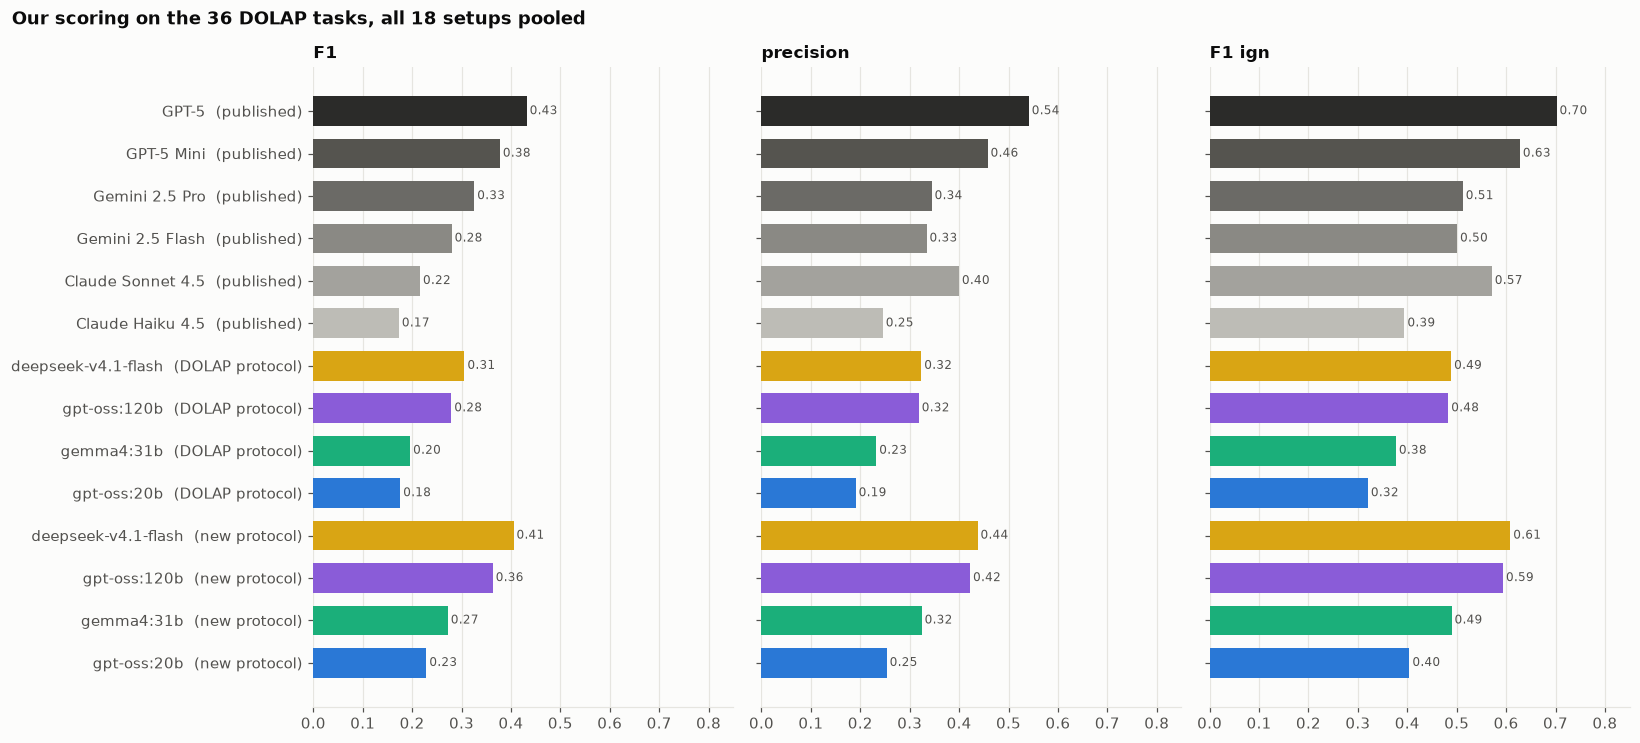

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 0.36 * len(head) + 1.8), sharey=True)
lab = [f"{m}  ({'published' if s.startswith('DOLAP') else s.split(', ')[1]})" for s, m in zip(head.source, head.model)]
y = np.arange(len(head))
for ax, col in zip(axes, ["F1", "precision", "F1 ign"]):
    ax.barh(y, head[col], color=[COLOR[m] for m in head.model], height=0.7)
    for yi, v in zip(y, head[col]):
        ax.text(v + 0.006, yi, f"{v:.2f}", va="center", fontsize=8, color=L.INK2)
    ax.set_title(col); ax.set_xlim(0, 0.85); ax.grid(axis="y", visible=False)
axes[0].set_yticks(y, lab); axes[0].invert_yaxis()
fig.suptitle("Our scoring on the 36 DOLAP tasks, all 18 setups pooled", x=0.01, ha="left")
fig.tight_layout(); plt.show()

**On the same 36 tasks and with the same prompts, the open-weight models are in the range of the proprietary models; only GPT-5 and GPT-5 Mini stay clearly ahead.**

- **DOLAP protocol** (published prompts, 5 runs, all 18 setups pooled, our scoring):
  - deepseek-v4.1-flash F1 0.31 and gpt-oss:120b 0.28 sit between Gemini 2.5 Pro (0.33) and Gemini 2.5 Flash (0.28);
  - gemma4:31b (0.20) and gpt-oss:20b (0.18) sit at the level of the two Claude models (0.17–0.22);
  - GPT-5 (0.43) and GPT-5 Mini (0.38) remain ahead.
- **The open-weight models guess more.** They abstain on 10–27% of the hidden properties, against 10–63% for the proprietary models, and are wrong on 53–69%. Their precision is 0.19–0.32, against 0.25–0.54.
- **New protocol** (Figure 2 prompts with property notes, v5 examples, repair, 3 runs): every model gains, and deepseek-v4.1-flash reaches F1 0.41 (precision 0.44), between GPT-5 Mini and GPT-5. gpt-oss:120b reaches 0.36.
- **The DOLAP scoring tells the same story with larger numbers.** Pooled DOLAP F1 is 0.34–0.58 for the open-weight models with the published prompts and 0.42–0.63 with the new ones, against 0.44–0.67 for the proprietary models.

## 3. Table 3 of the paper, extended

The paper's way: for each model, the setup with the best DOLAP F1, with the number of compared properties it rests on.
Next to it, our metrics of that same setup, and our F1 of the model's best setup chosen by our F1.

In [6]:
cfg = score(["source", "model", "context", "prompt"]).reset_index()
rows = []
for (s, m), g in cfg.groupby(["source", "model"]):
    b = g.sort_values(["DOLAP F1", "compared"], ascending=False).iloc[0]
    o = g.sort_values("F1", ascending=False).iloc[0]
    rows.append({"source": s, "model": m, "best setup (DOLAP F1)": f"{b.prompt}{' + ctx' if b.context else ''}",
                 "DOLAP F1": b["DOLAP F1"], "compared": int(b.compared), "its F1": b.F1, "its precision": b.precision,
                 "best F1 (any setup)": o.F1, "pooled F1": head.set_index(["source", "model"]).loc[(s, m), "F1"]})
t3 = pd.DataFrame(rows).sort_values(["source", "DOLAP F1"], ascending=[True, False])
t3.round(3)

,source,model,best setup (DOLAP F1),DOLAP F1,compared,its F1,its precision,best F1 (any setup),pooled F1
1,DOLAP (published),Claude Sonnet 4.5,1-shot + CoT + ctx,0.800,3,0.040,0.667,0.407,0.216
2,DOLAP (published),GPT-5,3-shot + CoT,0.674,59,0.466,0.585,0.484,0.432
5,DOLAP (published),Gemini 2.5 Pro,5-shot + CoT + ctx,0.656,43,0.337,0.359,0.386,0.326
4,DOLAP (published),Gemini 2.5 Flash,5-shot + CoT + ctx,0.613,52,0.304,0.343,0.346,0.280
3,DOLAP (published),GPT-5 Mini,5-shot + CoT,0.600,49,0.400,0.577,0.427,0.378
0,DOLAP (published),Claude Haiku 4.5,3-shot + CoT,0.550,29,0.120,0.368,0.319,0.173
6,"lineup, DOLAP protocol",deepseek-v4.1-flash,5-shot + CoT + ctx,0.664,143,0.330,0.344,0.356,0.306
8,"lineup, DOLAP protocol",gpt-oss:120b,5-shot + CoT + ctx,0.505,80,0.314,0.333,0.335,0.279
9,"lineup, DOLAP protocol",gpt-oss:20b,5-shot + ctx,0.463,113,0.199,0.204,0.254,0.176
7,"lineup, DOLAP protocol",gemma4:31b,zero-shot + ctx,0.404,75,0.240,0.259,0.247,0.196


## 4. The protocol: published prompts or the new prompts, same models and tasks

The lineup's two runs differ only in the prompt protocol (and 5 against 3 runs). Positive = the new protocol scores higher.

In [7]:
lin = score(["source", "model", "context"]).reset_index()
lin = lin[lin.source.str.startswith("lineup")]
if lin.source.nunique() == 2:
    pv = lin.pivot_table(index=["model", "context"], columns="source", values=["F1", "precision", "F1 ign", "abstention"])
    diff = pd.DataFrame({k: pv[(k, "lineup, new protocol")] - pv[(k, "lineup, DOLAP protocol")] for k in ["F1", "precision", "F1 ign", "abstention"]})
    display(pv.round(3))
    print("new protocol minus DOLAP protocol:")
    display(diff.round(3))
else:
    print("needs both lineup runs")

F1                                      F1 ign                                  abstention                                   precision                     
source                      lineup, DOLAP protocol lineup, new protocol lineup, DOLAP protocol lineup, new protocol lineup, DOLAP protocol lineup, new protocol lineup, DOLAP protocol lineup, new protocol
model               context                                                                                                                                                                                
deepseek-v4.1-flash False                    0.303                0.421                  0.494                0.644                  0.139                0.202                  0.328                0.474
                    True                     0.308                0.390                  0.484                0.577                  0.066                0.071                  0.319                0.405
gemma4:31b          False                    0.168                0.242                  0.341                0.466                  0.311                0.340                  0.206                0.304
                    True                     0.223                0.301                  0.408                0.509                  0.230                0.212                  0.256                0.341
gpt-oss:120b        False                    0.263                0.349                  0.488                0.611                  0.311                0.342                  0.322                0.440
                    True                     0.294                0.376                  0.479                0.580                  0.126                0.149                  0.315                0.409
gpt-oss:20b         False                    0.142                0.188                  0.281                0.363                  0.229                0.263                  0.163                0.222
                    True                     0.207                0.266                  0.352                0.437                  0.059                0.091                  0.213                0.279

new protocol minus DOLAP protocol:


F1  precision  F1 ign  abstention
model               context                                     
deepseek-v4.1-flash False   0.118      0.146   0.149       0.062
                    True    0.082      0.086   0.093       0.006
gemma4:31b          False   0.074      0.099   0.125       0.029
                    True    0.078      0.085   0.101      -0.018
gpt-oss:120b        False   0.086      0.117   0.123       0.032
                    True    0.082      0.094   0.101       0.023
gpt-oss:20b         False   0.046      0.058   0.082       0.034
                    True    0.059      0.066   0.085       0.032

**The new protocol raises every model, by F1 +0.05 to +0.12 and precision +0.06 to +0.15, in both conditions.**

- The gain is largest for deepseek-v4.1-flash (+0.12 F1 without context) and gpt-oss:120b (+0.09), smallest for gpt-oss:20b (+0.05).
- Abstention changes little (−0.02 to +0.06): the new prompts mostly turn wrong answers into correct ones.
- The two protocols differ in several ways at once (prompt wording, property notes for `source`, `dst` and `timezone`, few-shot examples, a repair call, 3 instead of 5 runs), so this comparison does not isolate one of them.
- The DOLAP-protocol run of gpt-oss:20b reuses 18 runs of a 27 Oct connection test made with `max_tokens` 1024 instead of 4096 (one run of one task per setup, 18 of 3,240 runs).

## 5. Context

Same tasks and prompts, with and without the published context block. For the Gemini models only the 4 airports
present in both conditions are used. Positive = context helps.

In [8]:
def same_airports(df):
    keep = []
    for (s, m), g in df.groupby(["source", "model"]):
        both = set(g[g.context].node) & set(g[~g.context].node)
        keep.append(g[g.node.isin(both)])
    return pd.concat(keep)

ss_c, sp_c = same_airports(ss), same_airports(sp)
cx = score(["source", "model", "context"], ss_c, sp_c).reset_index()
pv = cx.pivot_table(index=["source", "model"], columns="context", values=["F1", "precision", "abstention", "DOLAP F1"])
ctx_delta = pd.DataFrame({k: pv[(k, True)] - pv[(k, False)] for k in ["F1", "precision", "abstention", "DOLAP F1"]})
ctx_delta.round(3)

F1  precision  abstention  DOLAP F1
source                 model                                                      
DOLAP (published)      Claude Haiku 4.5     0.077      0.052      -0.203     0.117
                       Claude Sonnet 4.5    0.003     -0.007      -0.015     0.015
                       GPT-5               -0.029     -0.040      -0.007    -0.026
                       GPT-5 Mini          -0.024     -0.136      -0.269    -0.056
                       Gemini 2.5 Flash     0.017     -0.047      -0.258    -0.038
                       Gemini 2.5 Pro       0.088      0.072      -0.104     0.098
lineup, DOLAP protocol deepseek-v4.1-flash  0.005     -0.009      -0.074     0.024
                       gemma4:31b           0.055      0.051      -0.080     0.091
                       gpt-oss:120b         0.031     -0.007      -0.185     0.057
                       gpt-oss:20b          0.065      0.050      -0.170     0.087
lineup, new protocol   deepseek-v4.1-flash -0.031     -0.069      -0.130    -0.054
                       gemma4:31b           0.059      0.037      -0.128     0.061
                       gpt-oss:120b         0.027     -0.031      -0.194     0.007
                       gpt-oss:20b          0.078      0.058      -0.172     0.086

In [9]:
q = score(["source", "model", "context", "difficulty_prop"], ss_c, sp_c).reset_index()
hh = q[q.difficulty_prop == "hardhard"].pivot_table(index=["source", "model"], columns="context", values=["F1", "precision", "DOLAP F1"])
print("Hard H / hard G quadrant only (the paper's claim: context helps there):")
pd.DataFrame({k: hh[(k, True)] - hh[(k, False)] for k in ["DOLAP F1", "F1", "precision"]}).round(3)

Hard H / hard G quadrant only (the paper's claim: context helps there):


DOLAP F1     F1  precision
source                 model                                          
DOLAP (published)      Claude Haiku 4.5        0.147 -0.008     -0.131
                       Claude Sonnet 4.5       0.074 -0.012     -0.057
                       GPT-5                   0.042 -0.044     -0.182
                       GPT-5 Mini              0.119  0.035     -0.262
                       Gemini 2.5 Flash        0.449  0.134      0.050
                       Gemini 2.5 Pro          0.206  0.115      0.112
lineup, DOLAP protocol deepseek-v4.1-flash     0.133  0.037      0.027
                       gemma4:31b              0.078  0.056     -0.013
                       gpt-oss:120b            0.189  0.057     -0.052
                       gpt-oss:20b             0.058  0.028     -0.015
lineup, new protocol   deepseek-v4.1-flash     0.006  0.023     -0.049
                       gemma4:31b             -0.004  0.065     -0.069
                       gpt-oss:120b            0.270  0.129      0.070
                       gpt-oss:20b            -0.012  0.039     -0.009

**On the DOLAP tasks, where context is added to the airport's own properties, context helps slightly; in the paper's task set, where it replaces them, it hurts.**

- With the published prompts, context raises the F1 of all four open-weight models (+0.005 to +0.065), mostly by lowering abstention (−7 to −19 points).
- With the new prompts, it helps three models (+0.03 to +0.08) and lowers deepseek-v4.1-flash (−0.03).
- For the proprietary models the effect is mixed (−0.03 to +0.09).
- In the hard H / hard G quadrant, the DOLAP F1 rises for every open-weight model with the published prompts (+0.06 to +0.19), as in the DOLAP paper; with our F1 the gains are smaller (+0.03 to +0.06) and precision often falls.
- This supports the explanation given in the paper: in the DOLAP design the context block is extra information about neighbouring airports, whereas in the new task set context properties take the place of the airport's own properties.

## 6. Difficulty quadrants

Our F1 per H/G quadrant (easy/hard = popularity of the hidden / given properties), all setups.

In [10]:
QN = {"easyeasy": "H easy, G easy", "easyhard": "H easy, G hard", "hardeasy": "H hard, G easy", "hardhard": "H hard, G hard"}
qq = score(["source", "model", "difficulty_prop"]).reset_index()
qt = qq.pivot_table(index=["source", "model"], columns="difficulty_prop", values="F1").rename(columns=QN)
qt.round(3)

difficulty_prop                             H easy, G easy  H easy, G hard  H hard, G easy  H hard, G hard
source                 model                                                                              
DOLAP (published)      Claude Haiku 4.5              0.229           0.135           0.221           0.092
                       Claude Sonnet 4.5             0.234           0.225           0.262           0.130
                       GPT-5                         0.460           0.372           0.648           0.100
                       GPT-5 Mini                    0.307           0.340           0.586           0.225
                       Gemini 2.5 Flash              0.247           0.193           0.488           0.120
                       Gemini 2.5 Pro                0.288           0.251           0.574           0.156
lineup, DOLAP protocol deepseek-v4.1-flash           0.331           0.256           0.487           0.125
                       gemma4:31b                    0.166           0.072           0.364           0.174
                       gpt-oss:120b                  0.172           0.277           0.474           0.144
                       gpt-oss:20b                   0.157           0.131           0.278           0.123
lineup, new protocol   deepseek-v4.1-flash           0.514           0.390           0.515           0.148
                       gemma4:31b                    0.429           0.157           0.326           0.148
                       gpt-oss:120b                  0.447           0.383           0.438           0.136
                       gpt-oss:20b                   0.272           0.216           0.305           0.092

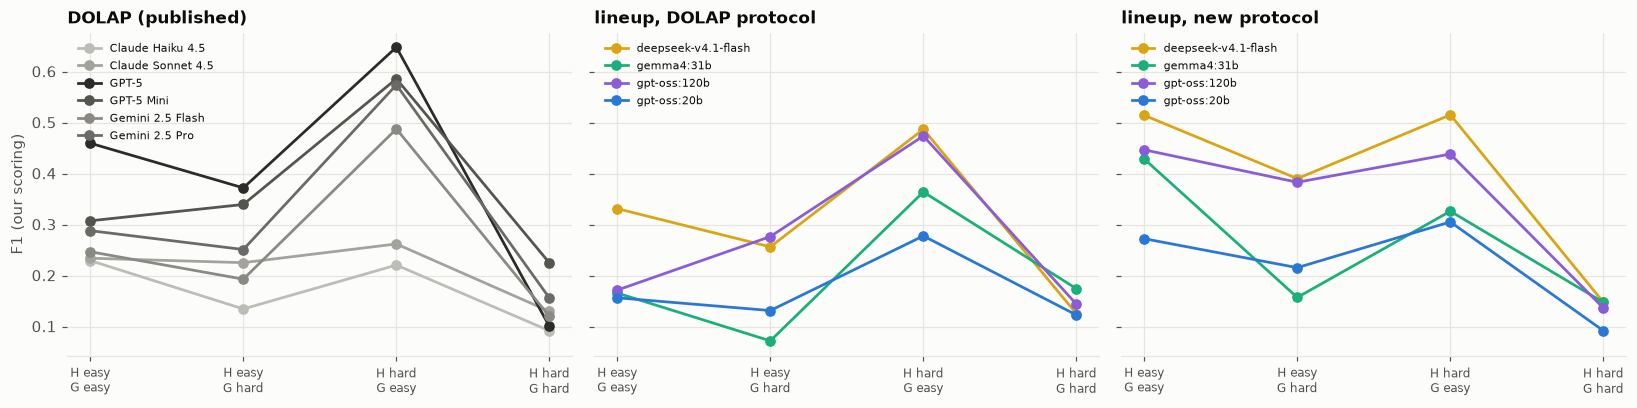

In [11]:
fig, axes = plt.subplots(1, len(SOURCES), figsize=(5 * len(SOURCES), 3.8), sharey=True)
axes = np.atleast_1d(axes)
for ax, s in zip(axes, SOURCES):
    sub = qq[qq.source == s]
    for m, g in sub.groupby("model"):
        g = g.set_index("difficulty_prop").reindex(list(QN))
        ax.plot(range(4), g.F1, marker="o", color=COLOR[m], label=m, lw=1.8)
    ax.set_xticks(range(4), [v.replace(", ", "\n") for v in QN.values()], fontsize=8)
    ax.set_title(s); ax.legend(fontsize=7.5, loc="upper left")
axes[0].set_ylabel("F1 (our scoring)")
fig.tight_layout(); plt.show()

**On the DOLAP tasks, the H/G quadrants are not ordered by difficulty for most models.**

- H hard / G hard is the hardest quadrant for most models (F1 0.09–0.23).
- H hard / G easy is the easiest quadrant for 11 of the 14 model–protocol combinations (up to F1 0.65 for GPT-5). The DOLAP 'hard' hidden properties (`iata`, number of runways) are easy once the airport is identified.
- This is the same pattern as in the published results, and one reason the new paper uses a global difficulty measure instead of these quadrants.

## 7. Prompts

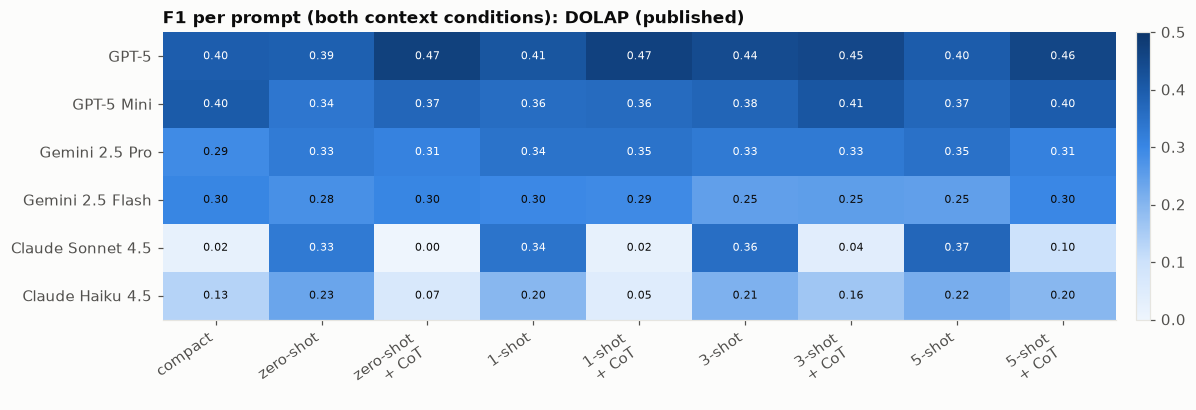

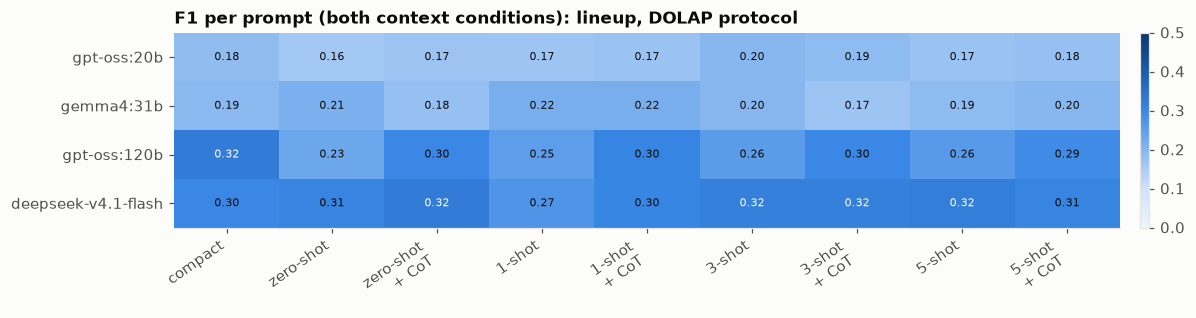

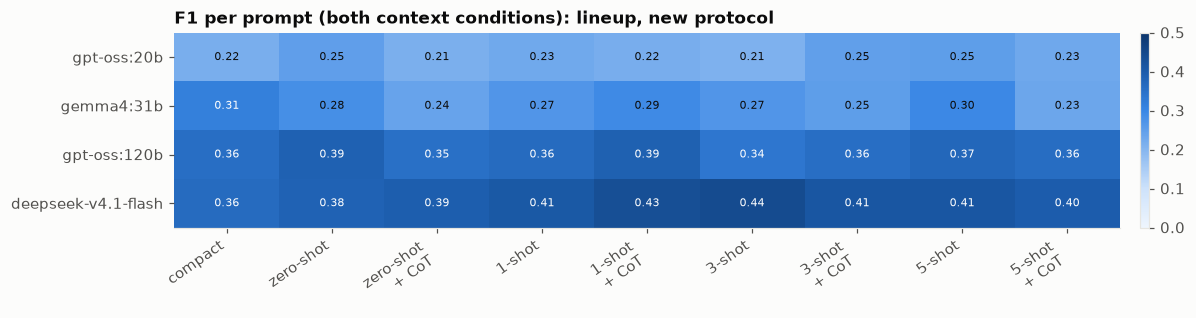

In [12]:
pp = score(["source", "model", "prompt"]).reset_index()
for s in SOURCES:
    piv = pp[pp.source == s].pivot_table(index="model", columns="prompt", values="F1").reindex(columns=PORDER)
    piv = piv.reindex([m for m in MODELS if m in piv.index])
    fig, ax = plt.subplots(figsize=(11, 0.42 * len(piv) + 1.3))
    L.heat(ax, piv, vmin=0, vmax=0.5, xlabels=[c.replace(" + ", "\n+ ") for c in piv.columns])
    ax.set_title(f"F1 per prompt (both context conditions): {s}")
    fig.tight_layout(); plt.show()

**No prompt is best across models.** The best prompt changes with the model and the protocol, and differences between prompts of one model are of the order of 0.1 F1, as on the paper's task set.

## 8. Properties

Recall (share found) per asked property, all setups. `n` = how many of each property the 36 tasks ask (per setup).

In [13]:
pr = ss.assign(found=ss.outcome.eq("correct")).pivot_table(index="property", columns="model", values="found", aggfunc="mean")
pr = pr.reindex(columns=[m for m in MODELS if m in pr.columns])
pr.insert(0, "n", ss[(ss.model == ss.model.iloc[0]) & (ss.source == ss.source.iloc[0])].groupby("property").size() / 18)
print("Lineup columns: both protocols together.")
pr.round(2)

Lineup columns: both protocols together.


model,n,gpt-oss:20b,gemma4:31b,gpt-oss:120b,deepseek-v4.1-flash,GPT-5,GPT-5 Mini,Gemini 2.5 Pro,Gemini 2.5 Flash,Claude Sonnet 4.5,Claude Haiku 4.5
property,,,,,,,,,,,
altitude,6.000,0.180,0.100,0.370,0.340,0.690,0.580,0.120,0.110,0.370,0.220
city,5.000,0.310,0.310,0.360,0.390,0.460,0.400,0.510,0.430,0.200,0.230
commercial_flights,2.000,0.010,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
country,4.000,0.440,0.190,0.640,0.650,0.570,0.720,0.470,0.530,0.240,0.360
distCity,2.000,0.080,0.400,0.210,0.220,0.000,0.000,0.000,0.000,0.000,0.000
dst,1.000,0.500,0.220,0.500,0.420,0.670,0.000,0.000,0.000,0.000,0.000
iata,15.000,0.130,0.170,0.290,0.340,0.530,0.410,0.500,0.320,0.170,0.080
latitude,5.000,0.200,0.300,0.140,0.430,0.720,0.320,0.470,0.380,0.230,0.330
location,2.000,0.000,0.000,0.010,0.000,0.030,0.000,0.310,0.000,0.030,0.000


## 9. The same models on the paper's airport task set

With models and prompts held fixed (lineup, new protocol), what remains between the DOLAP tasks and the airport tasks of
the paper is the task set itself. Airport results: the 108 resampled tasks (`data/new-diff-airports_ressampled.csv`) of
`results/airports/v5_ctx/scored/scored_voted.csv` (Strategy A, all 9 prompts, 3 runs; the DOLAP runs here use 3 runs too).
Note that the context condition is designed differently: in DOLAP the context block is added to the airport's own
properties; in v5 context properties replace some of them (|G| fixed).

In [14]:
rows = []
RESAMPLED = set(pd.read_csv(ROOT / "data/new-diff-airports_ressampled.csv").taskID)   # the 108 airport tasks used in the paper
s5 = pd.read_csv(ROOT / "results/airports/v5_ctx/scored/scored_voted.csv", low_memory=False)
s5 = s5[s5.strategy.eq("A") & s5.model.isin(LINEUP) & s5.task_id.isin(RESAMPLED)].assign(model=lambda d: d.model.map(L.MNAME))
for m, g in s5.groupby("model"):
    rows.append({"model": m, "task set": "airports, 108 resampled tasks", **ours(g).to_dict()})
new = ss[ss.source == "lineup, new protocol"]
for (m, c), g in new.groupby(["model", "context"]):
    rows.append({"model": m, "task set": "DOLAP 36, " + ("with context" if c else "no context"), **ours(g).to_dict()})
cmp5 = pd.DataFrame(rows)
cmp5.pivot_table(index="model", columns="task set", values="F1").round(3)

task set,"DOLAP 36, no context","DOLAP 36, with context","airports, 108 resampled tasks"
model,,,
deepseek-v4.1-flash,0.421,0.390,0.238
gemma4:31b,0.242,0.301,0.235
gpt-oss:120b,0.349,0.376,0.247
gpt-oss:20b,0.188,0.266,0.201


In [15]:
cmp5.pivot_table(index="model", columns="task set", values="precision").round(3)

task set,"DOLAP 36, no context","DOLAP 36, with context","airports, 108 resampled tasks"
model,,,
deepseek-v4.1-flash,0.474,0.405,0.284
gemma4:31b,0.304,0.341,0.380
gpt-oss:120b,0.440,0.409,0.403
gpt-oss:20b,0.222,0.279,0.263


**With models and prompts held fixed, the DOLAP tasks are easier than the paper's 108 airport tasks.**

- With the new protocol, F1 on the 36 DOLAP tasks (both conditions pooled) is 0.23–0.41, against 0.20–0.25 on the 108 resampled tasks.
- The gap is largest for deepseek-v4.1-flash (+0.17) and gpt-oss:120b (+0.12), and small for gpt-oss:20b (+0.03).
- Precision is clearly higher on the DOLAP tasks only for deepseek-v4.1-flash (0.41–0.47 against 0.28); for the other three models it is similar or lower (gemma4:31b 0.30–0.34 against 0.38), so their F1 gain does not come from fewer wrong answers.
- The DOLAP tasks ask more often for properties that follow from identifying the airport (`iata` is 15 of the 98 scored hidden properties per setup) and give the airport's own properties in G; the 108 tasks contain many `commercial_flights` targets and context-heavy G.

## 10. Tokens and cost

In [16]:
use = []
for proto, path in RES.items():
    if (path / "results.csv").exists():
        r = pd.read_csv(path / "results.csv")
        r = r[r.model.isin(LINEUP)]
        use.append(r.groupby("model").agg(runs=("run_index", "size"), tokens_in=("tokens_in", "sum"),
                                          tokens_out=("tokens_out", "sum")).assign(protocol=proto))
if use:
    use = pd.concat(use).reset_index()
    import yaml
    price = {}
    for f in ["configs/strategy_a_dolap2026.yaml", "configs/strategy_a_dolap2026_newprompts.yaml"]:
        for m in yaml.safe_load(open(ROOT / f))["models"]:
            if "pricing" in m:
                price[m["id"]] = m["pricing"]
    use["cost USD (list price)"] = [r.tokens_in / 1e6 * price[r.model]["input_per_mtok"] + r.tokens_out / 1e6 * price[r.model]["output_per_mtok"]
                                    for r in use.itertuples()]
    use["model"] = use.model.map(L.MNAME)
    display(use.round(3))

,model,runs,tokens_in,tokens_out,protocol,cost USD (list price)
0,deepseek-v4.1-flash,3240,1299779,80387,"lineup, DOLAP protocol",0.486
1,gemma4:31b,3240,1368045,79175,"lineup, DOLAP protocol",0.223
2,gpt-oss:120b,3240,1468215,477707,"lineup, DOLAP protocol",0.507
3,gpt-oss:20b,3240,1468215,586490,"lineup, DOLAP protocol",0.279
4,deepseek-v4.1-flash,1944,854156,42044,"lineup, new protocol",0.307
5,gemma4:31b,1944,911601,39314,"lineup, new protocol",0.143
6,gpt-oss:120b,1944,954573,286052,"lineup, new protocol",0.315
7,gpt-oss:20b,1944,966919,375559,"lineup, new protocol",0.180


## 11. Conclusions

**Answers to the three questions behind this run.**

1. **Are the new models worse than the proprietary ones?** On the same tasks, prompts and scoring, the best open-weight model (deepseek-v4.1-flash, F1 0.31) is at the level of Gemini 2.5 Pro, and gpt-oss:120b at the level of Gemini 2.5 Flash; only GPT-5 and GPT-5 Mini stay clearly ahead. The open-weight models abstain less and are wrong more often, so their precision is lower.
2. **Why are the new paper's numbers so much lower than DOLAP's Table 3?** Mostly because of the scoring and the best-of-18 selection (see `docs/DOLAP_GAP_ANALYSIS.md`), then the task set: the same models with the same prompts score 0.03–0.17 F1 higher on the DOLAP tasks than on the 108 resampled tasks.
3. **Do the new prompts matter?** Yes: on the DOLAP tasks they raise every model by 0.05–0.12 F1.

**Costs:** about $2.4 at list prices for the 20,736 runs (both protocols, four models).